# Ejercicio 4: ampliaciones

Se desarrollan las tres ideas del enunciado, en orden de solidez de los resultados:

* **Idea B.** Recompensas para no dejar volumen pendiente y consumir en torno al 90 % del tiempo.
* **Idea C.** Parada del entrenamiento por aprendizaje, guardado periódico de pesos y recuperación.
* **Idea A.** Estado ampliado con información del libro y la tendencia, y recompensa que premia el precio, para intentar mejorar el VWAP.

## Bloques modificados

| Idea | Bloque | Cambio | Fichero |
|---|---|---|---|
| B | `_plan_volume`, (6), (12) | `target_horizon`: el plan es lineal hasta `h·T` y plano después; la recompensa y el cierre usan ese plan | `env.py` |
| B | `TWAP` | `horizon`: benchmark determinista con el mismo plan comprimido | `agents.py` |
| C | Bucle | `train_with_evaluation`: `stop_ratio`, `stop_patience`, `checkpoint_dir`, `checkpoint_every`, `resume_from` | `train.py` |
| C | Checkpoints | `save_checkpoint` y `load_checkpoint`: pesos, optimizador, estado de ε, historial, buffer y RNG | `train.py` |
| A | (3) | `state_mode="market"`: spread, desequilibrio del libro y retorno de 1 minuto | `env.py` |
| A | (6) | `dev_band` (holgura sin coste alrededor del plan) y `price_weight` (premio en pbs por comprar por debajo del VWAP del episodio) | `env.py` |

In [1]:
from pathlib import Path
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# src al path, relativo a la raíz del repositorio
repo_root = Path.cwd().resolve()
if not (repo_root / "src").exists():
    repo_root = repo_root.parent
if str(repo_root / "src") not in sys.path:
    sys.path.insert(0, str(repo_root / "src"))

from execution_rl import *  # noqa: F403
from execution_rl.experiments import (
    PANEL_SEEDS,
    ExperimentConfig,
    build_agent,
    build_env,
    build_scheduler,
    eval_curves,
    restore_agent,
    run_many,
    save_results_table,
    twap_panel,
    with_seeds,
)

SEED = 42
set_seeds(SEED)
results_dir = repo_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)
# procesos para los barridos con varias semillas
N_JOBS = max(1, min(12, (os.cpu_count() or 2) - 2))
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print(f"Procesos en paralelo: {N_JOBS}")

Procesos en paralelo: 12


## Idea B: terminar en torno al 90 % del tiempo sin dejar volumen pendiente

**Motivación.** Un TWAP que apura hasta el último bin no deja margen: si al final falta liquidez o el agente se retrasa, queda volumen sin ejecutar. En la práctica se pide terminar algo antes, en el 70 a 90 % del tiempo, como se sugirió en clase.

**Cambio de recompensa.** En lugar de añadir premios sueltos ("terminar pronto", "no dejar pendiente"), que hay que calibrar entre sí y pueden competir, se cambia el **objetivo**: el plan pasa a ser `plan(t) = V·min(1, t/(h·T))` con `h = 0,9`, y la recompensa sigue siendo `-κ·|ejecutado - plan|`. Así:

* el episodio óptimo termina en `0,9·T` (después el plan vale `V` y cualquier pendiente cuesta en cada step);
* el castigo por pendiente al agotar el tiempo ($-\kappa\lambda P$) sigue activo como red de seguridad;
* la escala de la recompensa no cambia, por lo que valen la misma parametría y el mismo esquema de ε.

El estado no cambia: el desvío se mide respecto al nuevo plan, y el tiempo restante ya permite saber cuánto falta para `0,9·T`.

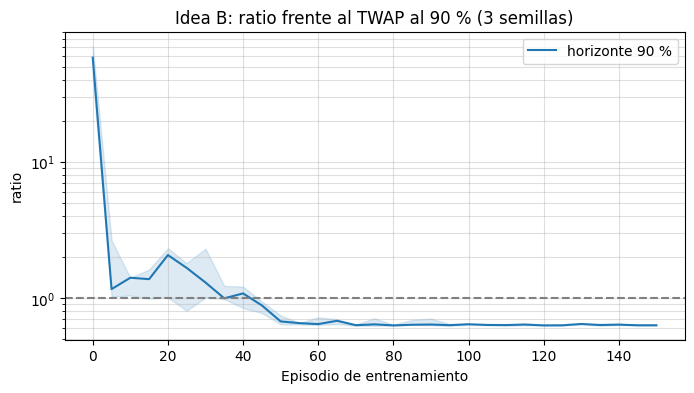

In [2]:
base = ExperimentConfig(name="horizonte 100 %", epsilon="adaptive", eps_min=0.02)
cfg_b = ExperimentConfig(name="horizonte 90 %", epsilon="adaptive", eps_min=0.02, target_horizon=0.9)
results_b = run_many(with_seeds(base, [0]) + with_seeds(cfg_b, [0, 1, 2]), n_jobs=N_JOBS)
curves_b = eval_curves(results_b)
save_results_table(curves_b, results_dir / "ej4b_curves.csv")
plot_eval_curves(curves_b[curves_b["name"] == cfg_b.name], "ratio", logy=True,
                 title="Idea B: ratio frente al TWAP al 90 % (3 semillas)").axhline(1.0, color="grey", ls="--")
plt.show()

In [3]:
robust_seeds = list(range(20_000, 20_200))
env_100, agent_100 = restore_agent(results_b[0])
env_90, agent_90 = restore_agent(results_b[1])
panels_b = {
    "agente, horizonte 100 %": evaluate_panel(env_100, agent_100, robust_seeds),
    "agente, horizonte 90 %": evaluate_panel(env_90, agent_90, robust_seeds),
    "TWAP determinista 90 %": twap_panel(env_90, robust_seeds, horizon=0.9),
}
summary_b = pd.DataFrame({k: summarize_panel(v) for k, v in panels_b.items()}).T
for k, v in panels_b.items():
    summary_b.loc[k, "time_used_pct_p5"] = v["time_used_pct"].quantile(0.05)
    summary_b.loc[k, "time_used_pct_p95"] = v["time_used_pct"].quantile(0.95)
    summary_b.loc[k, "órdenes incompletas"] = int((v["completed_pct"] < 100).sum())
save_results_table(summary_b.reset_index(names="política"), results_dir / "ej4b_summary.csv")
summary_b[["completed_pct", "órdenes incompletas", "time_used_pct", "time_used_pct_p5", "time_used_pct_p95", "mean_abs_dev", "slippage_bps_mean", "slippage_bps_std"]]

,completed_pct,órdenes incompletas,time_used_pct,time_used_pct_p5,time_used_pct_p95,mean_abs_dev,slippage_bps_mean,slippage_bps_std
"agente, horizonte 100 %",100.000,0.000,98.930,98.329,99.302,0.259,-3.314,6.475
"agente, horizonte 90 %",100.000,0.000,89.220,88.738,89.524,0.253,-3.415,6.894
TWAP determinista 90 %,100.000,0.000,88.440,87.740,88.927,0.404,-3.439,6.965


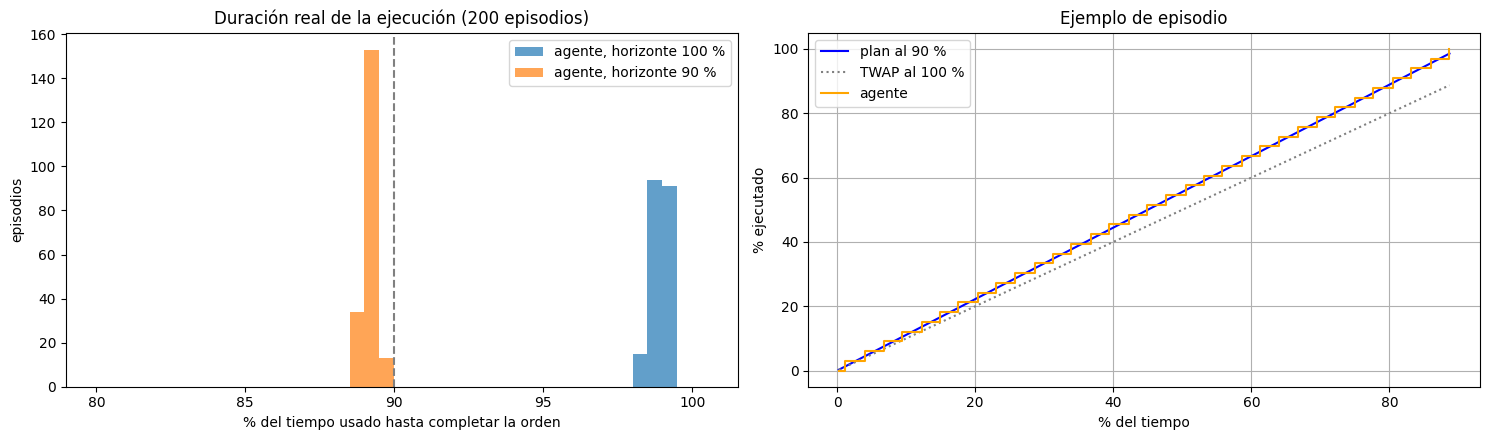

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for k in ["agente, horizonte 100 %", "agente, horizonte 90 %"]:
    axes[0].hist(panels_b[k]["time_used_pct"], bins=np.arange(80, 101, 0.5), alpha=0.7, label=k)
axes[0].axvline(90, color="grey", ls="--")
axes[0].set_xlabel("% del tiempo usado hasta completar la orden")
axes[0].set_ylabel("episodios")
axes[0].set_title("Duración real de la ejecución (200 episodios)")
axes[0].legend()
tr = episode_trace(env_90, agent_90, robust_seeds[0])
t_pct = 100 * tr["step"] / tr["episode_bins"]
axes[1].plot(t_pct, 100 * tr["plan"] / tr["vol_care"], color="blue", label="plan al 90 %")
axes[1].plot(t_pct, 100 * tr["step"] / tr["episode_bins"], color="grey", ls=":", label="TWAP al 100 %")
axes[1].step(t_pct, 100 * tr["exec_vol"] / tr["vol_care"], color="orange", where="post", label="agente")
axes[1].set_xlabel("% del tiempo")
axes[1].set_ylabel("% ejecutado")
axes[1].set_title("Ejemplo de episodio")
axes[1].legend()
axes[1].grid(True)
fig.tight_layout()
fig.savefig(results_dir / "ej4b_horizon.png", dpi=150, bbox_inches="tight")
plt.show()

El agente con horizonte del 90 % completa todas las órdenes y concentra la duración real de la ejecución en torno al 90 % del tiempo, frente a casi el 100 % del agente del Ejercicio 2, con un desvío frente a su plan del mismo orden. Expresar el objetivo como un plan distinto, en vez de añadir premios que compiten, evita la calibración delicada entre términos que menciona el enunciado: la escala de la recompensa no cambia y el entrenamiento es igual de estable.

## Idea C: parada por aprendizaje, guardado periódico y recuperación

**Parada.** Se reutiliza el criterio del Ejercicio 3: se para cuando la política greedy está por debajo de `stop_ratio = 0,7` veces el desvío del TWAP durante `stop_patience = 4` evaluaciones seguidas (20 episodios) **y** ε ya está en su suelo. Pedir varias evaluaciones seguidas evita parar por un panel afortunado, y exigir ε mínima asegura que se ha dejado de explorar. El número máximo de episodios (400) queda como tope de seguridad, no como duración prevista.

**Guardado.**
* `best.pt`: cada vez que mejora el ratio de evaluación (solo red, optimizador y ε). Es lo que se usa al final: protege frente a un deterioro tardío (olvido catastrófico).
* `last.pt`: cada 10 episodios y al parar, con todo lo necesario para reanudar exactamente: pesos de ambas redes, optimizador, estado de ε (incluida la aspiración), historial, buffer y estado de los generadores aleatorios.

Los ficheros se guardan en `results/ej4_checkpoints/` (excluido de git).

In [5]:
ckpt_dir = results_dir / "ej4_checkpoints"
cfg_c = ExperimentConfig(name="parada por aprendizaje", epsilon="adaptive", eps_min=0.02, seed=SEED)
set_seeds(cfg_c.seed)
env_c = build_env(cfg_c)
agent_c = build_agent(cfg_c, env_c)
sched_c = build_scheduler(cfg_c)
baseline_c = summarize_panel(twap_panel(env_c, cfg_c.panel_seeds))["mean_abs_dev"]
fill_buffer(env_c, agent_c, buffer_steps=cfg_c.buffer_fill, log_every=0)
hist_c, eval_c = train_with_evaluation(
    env_c, agent_c, sched_c,
    panel_seeds=cfg_c.panel_seeds, baseline_error=baseline_c,
    nepisodes=400, eval_every=5,
    checkpoint_dir=ckpt_dir / "early_stop", checkpoint_every=10,
    stop_ratio=0.7, stop_patience=4, n_log=10,
)
print(f"Episodios jugados: {len(hist_c['rewards'])} de un máximo de 400")
print(sorted(p.name for p in (ckpt_dir / "early_stop").iterdir()))

Episode: 0, steps: 508, rew: -350.61, mse: 0.5102, eps: 1.0, ratio vs TWAP: 57.707


Episode: 10, steps: 497, rew: -33.42, mse: 0.0339, eps: 0.265, ratio vs TWAP: 0.619


Episode: 20, steps: 572, rew: -34.67, mse: 0.0115, eps: 0.081, ratio vs TWAP: 0.625


Episode: 30, steps: 560, rew: -30.41, mse: 0.0073, eps: 0.045, ratio vs TWAP: 0.624


Episode: 40, steps: 555, rew: -31.16, mse: 0.0053, eps: 0.026, ratio vs TWAP: 0.683


Episode: 50, steps: 507, rew: -28.11, mse: 0.0002, eps: 0.022, ratio vs TWAP: 0.662


Episode: 54, steps: 572, rew: -30.09, mse: 0.0002, eps: 0.021, ratio vs TWAP: 0.631
Parada por aprendizaje en el episodio 54: ratio <= 0.7 en 4 evaluaciones seguidas
Episodios jugados: 55 de un máximo de 400
['best.pt', 'last.pt']


In [6]:
# se recupera el mejor modelo en un agente nuevo y se comprueba que rinde igual que en el momento de guardarlo
agent_best = build_agent(cfg_c, env_c)
ckpt_best = load_checkpoint(ckpt_dir / "early_stop" / "best.pt", agent_best)
best_row = ckpt_best["eval_rows"][-1]
check = summarize_panel(evaluate_panel(env_c, agent_best, cfg_c.panel_seeds))
print(f"best.pt guardado en el episodio {ckpt_best['episode']}: ratio {best_row['ratio']:.3f} al guardarlo, "
      f"{check['mean_abs_dev'] / baseline_c:.3f} al recuperarlo")

best.pt guardado en el episodio 9: ratio 0.619 al guardarlo, 0.619 al recuperarlo


**Reanudación.** Se simula una interrupción: un entrenamiento se corta en el episodio 40 y otro proceso, con un agente recién creado, lo retoma desde `last.pt` hasta el 80. Se compara con el mismo entrenamiento hecho de una vez: si la recuperación restaura todo el estado (incluidos buffer y semillas), las dos curvas coinciden.

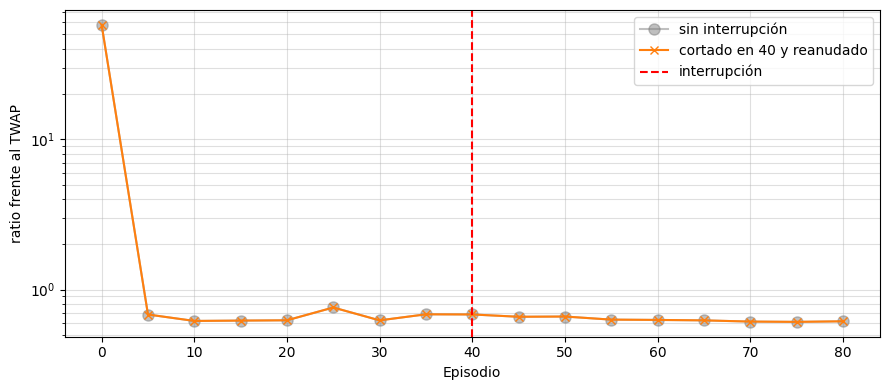

Curva reanudada idéntica a la continua: True (máx. diferencia 0.00e+00)


In [7]:
def train_segment(nepisodes: int, ckpt: Path, resume: bool) -> pd.DataFrame:
    """Entrena hasta nepisodes, guardando cada 10, opcionalmente reanudando desde last.pt."""
    set_seeds(cfg_c.seed)
    env_r = build_env(cfg_c)
    agent_r = build_agent(cfg_c, env_r)
    sched_r = build_scheduler(cfg_c)
    base_r = summarize_panel(twap_panel(env_r, cfg_c.panel_seeds))["mean_abs_dev"]
    if not resume:
        fill_buffer(env_r, agent_r, buffer_steps=cfg_c.buffer_fill, log_every=0)
    _, ev = train_with_evaluation(
        env_r, agent_r, sched_r, panel_seeds=cfg_c.panel_seeds, baseline_error=base_r,
        nepisodes=nepisodes, checkpoint_dir=ckpt, checkpoint_every=10,
        resume_from=ckpt / "last.pt" if resume else None, verbose=False,
    )
    return ev


ev_cut = train_segment(40, ckpt_dir / "resume", resume=False)       # se interrumpe en el episodio 40
ev_resumed = train_segment(80, ckpt_dir / "resume", resume=True)    # nuevo agente, retoma desde last.pt
ev_full = train_segment(80, ckpt_dir / "full", resume=False)        # referencia sin interrupción

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ev_full["episode"] + 1, ev_full["ratio"], "o-", color="grey", alpha=0.5, ms=8, label="sin interrupción")
ax.plot(ev_resumed["episode"] + 1, ev_resumed["ratio"], "x-", color="C1", label="cortado en 40 y reanudado")
ax.axvline(40, color="red", ls="--", label="interrupción")
ax.set_yscale("log")
ax.set_xlabel("Episodio")
ax.set_ylabel("ratio frente al TWAP")
ax.legend()
ax.grid(True, which="both", alpha=0.4)
fig.tight_layout()
fig.savefig(results_dir / "ej4c_resume.png", dpi=150, bbox_inches="tight")
plt.show()
same = np.allclose(ev_full["ratio"].values, ev_resumed["ratio"].values)
print(f"Curva reanudada idéntica a la continua: {same} (máx. diferencia {np.max(np.abs(ev_full['ratio'].values - ev_resumed['ratio'].values)):.2e})")

## Idea A: estado ampliado y recompensa de precio

**Motivación.** Un TWAP es indiferente al mercado. Si el agente puede adelantar o retrasar algunas compras dentro de un margen, podría comprar más cuando el precio está bajo y menos cuando está alto, y mejorar el VWAP sin alejarse demasiado del plan.

**Estado ampliado** (todo causal: solo información disponible en el bin actual o anterior):

| Variable | Definición | Por qué |
|---|---|---|
| spread | `(ask1 - bid1) / mid` en pbs, `/ 5`, acotado a [0, 3] | se compra a `ask1`: un spread estrecho abarata la compra |
| desequilibrio | `(vbid1 - vask1) / (vbid1 + vask1)` | presión compradora: más demanda que oferta anticipa subidas |
| tendencia | retorno del mid en los últimos 12 bins (1 minuto), en pbs `/ 10`, acotado a [-3, 3] | momentum o reversión de corto plazo |

**Recompensa.**

$$r_t = -\kappa \max(0,\ \lvert \text{desvío} \rvert - b) + w \cdot \mathbb{1}_{\text{compra}} \cdot \frac{\text{VWAP}_{ep} - p_t}{\text{VWAP}_{ep}} \cdot 10^4$$

con banda `b = 2` títulos (holgura sin coste para adelantar o retrasar compras) y `w = 0,05` por pb. El término de precio usa el VWAP del episodio completo, que no se conoce al decidir. **No es fuga de información:** no entra en el estado, solo en la señal de entrenamiento, y su suma sobre el episodio es `V·(VWAP_mercado - VWAP_algo)`, es decir, el slippage final de la orden, que sí se conoce al terminar. Repartirlo por compra es redistribuir una recompensa terminal para asignar mejor el crédito. La política solo puede usar lo que ve en el estado.

**Calibración.** Con `w = 0,05`, comprar 10 pbs mejor vale 0,5, lo mismo que 2,5 títulos de desvío fuera de banda en un step. Con pesos mayores (se probó 0,2) el agente se aleja del plan y deja órdenes incompletas.

**Exploración.** Se usa ε lineal (más episodios, 300): el criterio adaptativo del Ejercicio 3 mide solo el seguimiento del plan, que aquí se relaja a propósito; aplicarlo exigiría un ratio que incluya el precio.

**Evaluación.** La dispersión del slippage entre episodios es grande (depende de cómo se mueve el mercado ese día), así que se compara **en pareja**: agente y TWAP sobre los mismos episodios, y se mide la diferencia episodio a episodio. Se ajusta en train y se informa también en validación (2019), que el agente no ha visto.

El slippage solo mide lo ejecutado: una política que deja títulos sin comprar podría parecer mejor por no comprar los caros. Para comparar en igualdad se añade el **slippage con barrido final**: lo pendiente al terminar se compra al `ask1` del último bin, como haría un trader al cerrar la orden.

In [8]:
cfg_a = ExperimentConfig(name="estado de mercado + precio", state_mode="market", dev_band=2.0, price_weight=0.05,
                         nepisodes=300, eps_decay=1.0 / 250)
cfg_ref = ExperimentConfig(name="Ej. 2 (TWAP RL)", nepisodes=300, eps_decay=1.0 / 250)
results_a = run_many(with_seeds(cfg_a, [0, 1, 2]) + with_seeds(cfg_ref, [0]), n_jobs=N_JOBS)
save_results_table(eval_curves(results_a), results_dir / "ej4a_curves.csv")


def paired(agent_df: pd.DataFrame, twap_df: pd.DataFrame) -> dict[str, float]:
    """Diferencia de slippage agente - TWAP en los mismos episodios (positiva: el agente compra mejor)."""
    d = agent_df["slippage_bps"].values - twap_df["slippage_bps"].values
    # con barrido final: lo pendiente se compra al ask1 del último bin
    dc = agent_df["cleanup_slippage_bps"].values - twap_df["cleanup_slippage_bps"].values
    se = dc.std(ddof=1) / np.sqrt(len(dc))
    return {
        "slippage medio (pbs)": agent_df["slippage_bps"].mean(),
        "dispersión slippage (pbs)": agent_df["slippage_bps"].std(),
        "mejora sin barrido (pbs)": d.mean(),
        "mejora con barrido (pbs)": dc.mean(),
        "error estándar (pbs)": se,
        "t": dc.mean() / se if se > 0 else np.nan,
        "desvío medio (títulos)": agent_df["mean_abs_dev"].mean(),
        "% completado": agent_df["completed_pct"].mean(),
        "% órdenes completas": 100 * (agent_df["completed_pct"] >= 100).mean(),
    }


rows = []
for split, seeds_eval in [("train", list(range(20_000, 20_200))), ("val", list(range(30_000, 30_100)))]:
    env_ref, _ = restore_agent(results_a[0], split=split)
    twap_eval = twap_panel(env_ref, seeds_eval)
    rows.append({"split": split, "política": "TWAP determinista", **paired(twap_eval, twap_eval)})
    for res in results_a:
        env_s, agent_s = restore_agent(res, split=split)
        label = f"{res['config']['name']} (semilla {res['config']['seed']})"
        rows.append({"split": split, "política": label, **paired(evaluate_panel(env_s, agent_s, seeds_eval), twap_eval)})
summary_a = pd.DataFrame(rows).set_index(["split", "política"])
save_results_table(summary_a.reset_index(), results_dir / "ej4a_summary.csv")
summary_a

slippage medio (pbs)  \
split política                                                       
train TWAP determinista                                     -3.340   
      estado de mercado + precio (semilla 0)                -2.956   
      estado de mercado + precio (semilla 1)                -2.949   
      estado de mercado + precio (semilla 2)                -2.944   
      Ej. 2 (TWAP RL) (semilla 0)                           -3.318   
val   TWAP determinista                                     -1.834   
      estado de mercado + precio (semilla 0)                -1.396   
      estado de mercado + precio (semilla 1)                -1.709   
      estado de mercado + precio (semilla 2)                -1.405   
      Ej. 2 (TWAP RL) (semilla 0)                           -1.939   

                                              dispersión slippage (pbs)  \
split política                                                            
train TWAP determinista                                           6.558   
      estado de mercado + precio (semilla 0)                      6.797   
      estado de mercado + precio (semilla 1)                      6.540   
      estado de mercado + precio (semilla 2)                      6.469   
      Ej. 2 (TWAP RL) (semilla 0)                                 6.493   
val   TWAP determinista                                           4.589   
      estado de mercado + precio (semilla 0)                      4.288   
      estado de mercado + precio (semilla 1)                      4.870   
      estado de mercado + precio (semilla 2)                      4.528   
      Ej. 2 (TWAP RL) (semilla 0)                                 4.454   

                                              mejora sin barrido (pbs)  \
split política                                                           
train TWAP determinista                                          0.000   
      estado de mercado + precio (semilla 0)                     0.384   
      estado de mercado + precio (semilla 1)                     0.391   
      estado de mercado + precio (semilla 2)                     0.396   
      Ej. 2 (TWAP RL) (semilla 0)                                0.022   
val   TWAP determinista                                          0.000   
      estado de mercado + precio (semilla 0)                     0.438   
      estado de mercado + precio (semilla 1)                     0.126   
      estado de mercado + precio (semilla 2)                     0.429   
      Ej. 2 (TWAP RL) (semilla 0)                               -0.105   

                                              mejora con barrido (pbs)  \
split política                                                           
train TWAP determinista                                          0.000   
      estado de mercado + precio (semilla 0)                     0.274   
      estado de mercado + precio (semilla 1)                     0.359   
      estado de mercado + precio (semilla 2)                     0.299   
      Ej. 2 (TWAP RL) (semilla 0)                                0.022   
val   TWAP determinista                                          0.000   
      estado de mercado + precio (semilla 0)                     0.282   
      estado de mercado + precio (semilla 1)                     0.073   
      estado de mercado + precio (semilla 2)                     0.377   
      Ej. 2 (TWAP RL) (semilla 0)                               -0.105   

                                              error estándar (pbs)      t  \
split política                                                              
train TWAP determinista                                      0.000    NaN   
      estado de mercado + precio (semilla 0)                 0.100  2.736   
      estado de mercado + precio (semilla 1)                 0.064  5.589   
      estado de mercado + precio (semilla 2)                 0.065  4.624   
      Ej. 2 (TWAP RL) (semilla 0)                            0.0

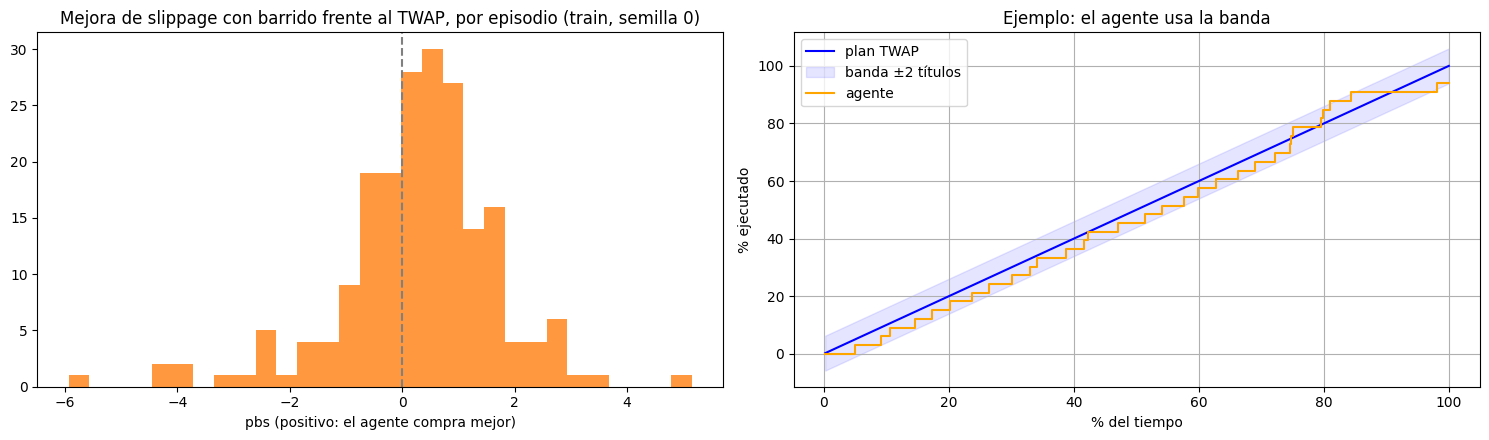

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
env_tr, agent_a = restore_agent(results_a[0], split="train")
seeds_eval = list(range(20_000, 20_200))
a_df = evaluate_panel(env_tr, agent_a, seeds_eval)
t_df = twap_panel(env_tr, seeds_eval)
axes[0].hist(a_df["cleanup_slippage_bps"] - t_df["cleanup_slippage_bps"], bins=30, color="C1", alpha=0.8)
axes[0].axvline(0, color="grey", ls="--")
axes[0].set_title("Mejora de slippage con barrido frente al TWAP, por episodio (train, semilla 0)")
axes[0].set_xlabel("pbs (positivo: el agente compra mejor)")
tr = episode_trace(env_tr, agent_a, seeds_eval[0])
t_pct = 100 * tr["step"] / tr["episode_bins"]
axes[1].plot(t_pct, 100 * tr["plan"] / tr["vol_care"], color="blue", label="plan TWAP")
band = 100 * 2.0 / tr["vol_care"].iloc[0]
axes[1].fill_between(t_pct, 100 * tr["plan"] / tr["vol_care"] - band, 100 * tr["plan"] / tr["vol_care"] + band,
                     color="blue", alpha=0.1, label="banda ±2 títulos")
axes[1].step(t_pct, 100 * tr["exec_vol"] / tr["vol_care"], color="orange", where="post", label="agente")
axes[1].set_title("Ejemplo: el agente usa la banda")
axes[1].set_xlabel("% del tiempo")
axes[1].set_ylabel("% ejecutado")
axes[1].legend()
axes[1].grid(True)
fig.tight_layout()
fig.savefig(results_dir / "ej4a_price.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura.**

* **Hay mejora, pequeña pero sistemática.** Sin barrido, las tres semillas compran unos 0,4 pbs mejor que el TWAP en train. Cobrando lo pendiente al final, la mejora baja a entre 0,27 y 0,36 pbs, con t entre 2,7 y 5,6: las tres semillas la mantienen. En validación (días de 2019 no vistos) se mantiene en dos semillas (+0,28 y +0,38 pbs); en la tercera es +0,07 pbs y no es significativa. El agente del Ejercicio 2, sin estado de mercado, no mejora el precio (+0,02 pbs en train y -0,10 en validación), lo que confirma que la mejora viene de las variables de mercado y del término de precio.
* **Tiene un coste en seguimiento.** El desvío medio frente al plan sube de 0,41 títulos (TWAP) a entre 0,7 y 1,3, y muchas órdenes acaban con 1 título pendiente: la banda de ±2 títulos deja quedarse algo por debajo del plan sin coste, también al final. Por eso se informa la métrica con barrido, que lo penaliza.
* **Es pequeña frente a la dispersión.** El slippage varía unos 6,5 pbs de un episodio a otro; 0,3 pbs es poco, aunque en una orden grande y repetida cada día se acumula. Con 60 días de un solo valor y variables de primera posición no cabe esperar mucho más; el enunciado ya advierte que pueden hacer falta más datos.

Siguientes pasos: estrechar la banda hacia el final del episodio (o hacerla asimétrica) para cerrar siempre la orden, más días y activos (`new_version/`, con 3 posiciones del libro y ejecuciones), variables de flujo, y un criterio de ε y de parada que combine seguimiento y precio.

## Resumen del Ejercicio 4

| Idea | Resultado |
|---|---|
| B | Órdenes completas al 100 % con la ejecución terminando en torno al 90 % del tiempo, cambiando el plan objetivo en lugar de añadir premios que compiten. |
| C | El entrenamiento para solo cuando la política supera de forma sostenida al benchmark; `best.pt` conserva el mejor modelo y `last.pt` permite reanudar con resultados idénticos a un entrenamiento continuo. |
| A | Estado de mercado causal y recompensa de precio sin fuga de información: unos 0,3 pbs de mejora frente al TWAP, cobrando lo pendiente, en 3 de 3 semillas en train y 2 de 3 en validación, a cambio de más desvío frente al plan. |